# Lab 5

## 1. Import the libraries

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


---

## 2. Read and prepare the image

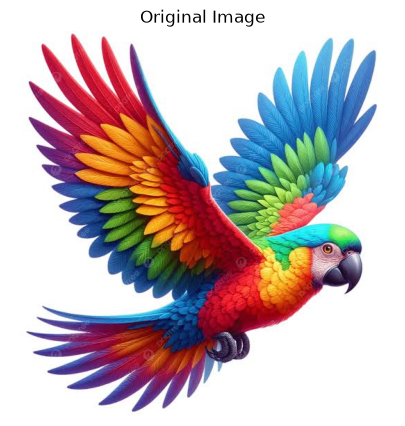

Image shape: (554, 554, 3)


In [3]:
image_path = Path("images/Parrot.png")  # Change this path if your image is elsewhere

image_bgr = cv2.imread(str(image_path))
if image_bgr is None:
    raise FileNotFoundError(
        f"Could not load image: {image_path.resolve()}\n"
        "Place an image at this path or update image_path to your image file."
    )

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)

---

## Task 1:

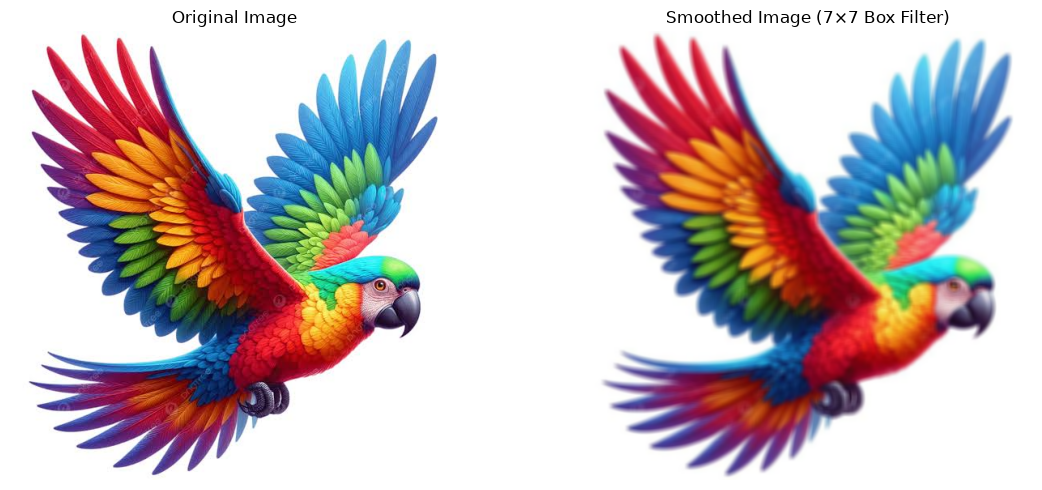

In [4]:
box_smoothed = cv2.blur(image, (7, 7))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(box_smoothed)
ax[1].set_title("Smoothed Image (7×7 Box Filter)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

---

## Task 2:

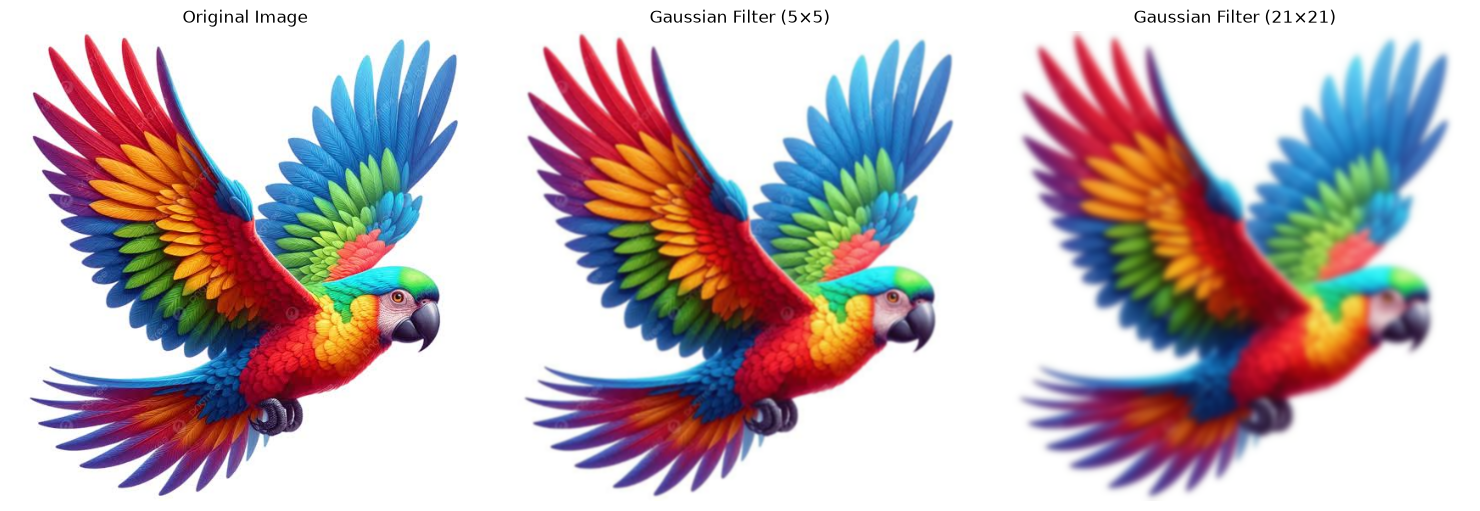

In [5]:
gaussian_5 = cv2.GaussianBlur(image, (5, 5), 0)
gaussian_21 = cv2.GaussianBlur(image, (21, 21), 0)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(gaussian_5)
ax[1].set_title("Gaussian Filter (5×5)")
ax[1].axis("off")

ax[2].imshow(gaussian_21)
ax[2].set_title("Gaussian Filter (21×21)")
ax[2].axis("off")

plt.tight_layout()
plt.show()

---

## Task 3:

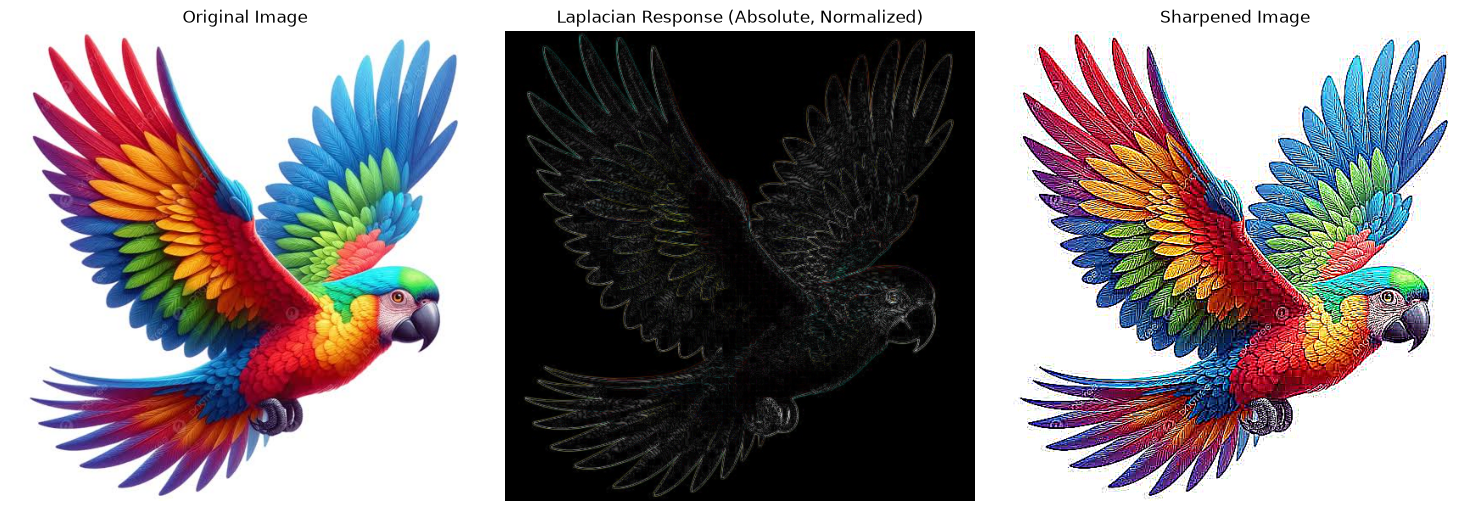

In [7]:
image_float = image.astype(np.float32) / 255.0

laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=3)

sharpened = np.clip(image_float - laplacian, 0, 1)

laplacian_display = np.abs(laplacian)
max_value = laplacian_display.max()
if max_value > 0:
    laplacian_display = laplacian_display / max_value

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image_float)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(laplacian_display)
ax[1].set_title("Laplacian Response (Absolute, Normalized)")
ax[1].axis("off")

ax[2].imshow(sharpened)
ax[2].set_title("Sharpened Image")
ax[2].axis("off")

plt.tight_layout()
plt.show()